# 🌍 Air Quality Forecasting Using Time Series Analysis

## 📌 Notebook 02 — Data Cleaning & Preprocessing

In this notebook, we will prepare the selected **Delhi daily AQI time series** for forecasting. Based on the data-understanding phase, Delhi was selected because it contains a long and continuous daily history from **2015-01-01 to 2020-07-01**, with only a small number of missing AQI observations. We will perform the necessary preprocessing steps, including loading the data, selecting Delhi, converting the date column to datetime, sorting the observations chronologically, checking missing values, handling the missing AQI observations appropriately, and preparing a clean time-series dataset for exploratory analysis and forecasting.

## 1. Import Required Libraries

We begin by importing the libraries required for data manipulation, visualization, and time-series preprocessing.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the Dataset

We will load the city-level daily air-quality dataset that was used during the data-understanding phase.

In [3]:
df = pd.read_csv("../data/raw/city_day.csv")
print("Dataset shape:", df.shape)

Dataset shape: (29531, 16)


## 3. Select Delhi AQI Data

Since Delhi was selected as our forecasting location during the data-understanding phase, we will extract only Delhi observations for the remainder of this notebook.

In [4]:
delhi = df[df["City"] == "Delhi"].copy()

print("Delhi dataset shape:", delhi.shape)

Delhi dataset shape: (2009, 16)


## 4. Create the Initial Forecasting Dataset

Our initial forecasting problem is **univariate AQI forecasting**, where historical AQI values are used to predict future AQI values. Therefore, we will initially retain only the `Date` and `AQI` variables.

In [5]:
delhi_ts = delhi[["Date", "AQI"]].copy()

delhi_ts.head()

,Date,AQI
10229,2015-01-01,472.0
10230,2015-01-02,454.0
10231,2015-01-03,143.0
10232,2015-01-04,319.0
10233,2015-01-05,325.0


In [6]:
delhi_ts.shape

(2009, 2)

In [7]:
delhi_ts["Date"].dtype

<StringDtype(storage='python', na_value=nan)>

## 5. Convert Date to Datetime

The `Date` column is currently stored as a string. Time-series operations require dates to be represented using a proper datetime format, which allows us to sort observations chronologically, calculate time differences, extract calendar features, and set the date as the time-series index.

In [8]:
delhi_ts["Date"] = pd.to_datetime(delhi_ts["Date"])

print(delhi_ts["Date"].dtype)

datetime64[us]


## 6. Sort Observations Chronologically

Time-series forecasting depends on the correct temporal order of observations. We therefore sort the dataset by date before performing any further analysis.

In [9]:
delhi_ts = delhi_ts.sort_values("Date").reset_index(drop=True)

delhi_ts.head()

,Date,AQI
0,2015-01-01,472.0
1,2015-01-02,454.0
2,2015-01-03,143.0
3,2015-01-04,319.0
4,2015-01-05,325.0


In [10]:
delhi_ts.tail()

,Date,AQI
2004,2020-06-27,112.0
2005,2020-06-28,196.0
2006,2020-06-29,233.0
2007,2020-06-30,114.0
2008,2020-07-01,101.0


## 7. Check for Duplicate Dates

A daily time series should contain at most one AQI observation for each date. We therefore check whether any dates occur more than once.

In [11]:
duplicate_dates = delhi_ts["Date"].duplicated().sum()

print("Duplicate dates:", duplicate_dates)

Duplicate dates: 0


## 8. Verify Daily Frequency

The selected dataset is expected to contain daily observations. We will calculate the difference between consecutive dates to verify that the time interval is consistent.

In [12]:
date_diff = delhi_ts["Date"].diff().dt.days

print("Minimum gap:", date_diff.min())
print("Maximum gap:", date_diff.max())
print("Number of gaps greater than 1 day:", (date_diff > 1).sum())

Minimum gap: 1.0
Maximum gap: 1.0
Number of gaps greater than 1 day: 0


## 9. Missing AQI Observations

Delhi contains only 10 missing AQI observations out of 2,009 daily observations. Since AQI is our forecasting target, we cannot simply replace these values without first understanding where they occur. We will inspect the missing dates before deciding how to handle them.

In [13]:
delhi_ts[delhi_ts["AQI"].isna()]

,Date,AQI
570,2016-07-24,NaN
904,2017-06-23,NaN
955,2017-08-13,NaN
956,2017-08-14,NaN
964,2017-08-22,NaN
965,2017-08-23,NaN
968,2017-08-26,NaN
969,2017-08-27,NaN
970,2017-08-28,NaN
971,2017-08-29,NaN


In [14]:
print("Missing AQI:", delhi_ts["AQI"].isna().sum())
print("Missing AQI %:", delhi_ts["AQI"].isna().mean() * 100)

Missing AQI: 10
Missing AQI %: 0.49776007964161273


## 10. Inspecting Missing AQI Periods

The missing AQI observations occur as both isolated missing days and short consecutive gaps. Before imputing these values, we will examine the observations immediately before and after each missing period. This will help us determine whether time-based interpolation is reasonable for preserving the local pattern of the AQI series.

In [15]:
missing_dates = delhi_ts.loc[delhi_ts["AQI"].isna(), "Date"]

for date in missing_dates:
    print("\nMissing date:", date.date())

    window = delhi_ts[
        (delhi_ts["Date"] >= date - pd.Timedelta(days=1)) &
        (delhi_ts["Date"] <= date + pd.Timedelta(days=1))
    ]

    print(window.to_string(index=False))


Missing date: 2016-07-24
      Date   AQI
2016-07-23 163.0
2016-07-24   NaN
2016-07-25 195.0

Missing date: 2017-06-23
      Date   AQI
2017-06-22 124.0
2017-06-23   NaN
2017-06-24 111.0

Missing date: 2017-08-13
      Date  AQI
2017-08-12 45.0
2017-08-13  NaN
2017-08-14  NaN

Missing date: 2017-08-14
      Date  AQI
2017-08-13  NaN
2017-08-14  NaN
2017-08-15 59.0

Missing date: 2017-08-22
      Date  AQI
2017-08-21 42.0
2017-08-22  NaN
2017-08-23  NaN

Missing date: 2017-08-23
      Date  AQI
2017-08-22  NaN
2017-08-23  NaN
2017-08-24 58.0

Missing date: 2017-08-26
      Date   AQI
2017-08-25 104.0
2017-08-26   NaN
2017-08-27   NaN

Missing date: 2017-08-27
      Date  AQI
2017-08-26  NaN
2017-08-27  NaN
2017-08-28  NaN

Missing date: 2017-08-28
      Date  AQI
2017-08-27  NaN
2017-08-28  NaN
2017-08-29  NaN

Missing date: 2017-08-29
      Date  AQI
2017-08-28  NaN
2017-08-29  NaN
2017-08-30 73.0


## 10. Handling Missing AQI Values

The Delhi time series contains 10 missing AQI observations. These missing values occur only within the series and are surrounded by valid observations. Since the gaps are short, with the longest gap being four consecutive days, we will use **time-based linear interpolation** to estimate the missing AQI values. This approach uses the temporal position of each observation and the surrounding AQI values while preserving the continuity of the time series.

In [16]:
delhi_ts = delhi_ts.set_index("Date")

In [17]:
delhi_ts.head()

,AQI
Date,
2015-01-01,472.0
2015-01-02,454.0
2015-01-03,143.0
2015-01-04,319.0
2015-01-05,325.0


In [18]:
delhi_ts["AQI"] = delhi_ts["AQI"].interpolate(method="time")

In [19]:
print("Missing AQI after interpolation:", delhi_ts["AQI"].isna().sum())

Missing AQI after interpolation: 0


In [20]:
delhi_ts.loc[
    ["2016-07-24",
     "2017-06-23",
     "2017-08-13",
     "2017-08-14",
     "2017-08-22",
     "2017-08-23",
     "2017-08-26",
     "2017-08-27",
     "2017-08-28",
     "2017-08-29"]
]

,AQI
Date,
2016-07-24,179.000000
2017-06-23,117.500000
2017-08-13,49.666667
2017-08-14,54.333333
2017-08-22,47.333333
2017-08-23,52.666667
2017-08-26,97.800000
2017-08-27,91.600000
2017-08-28,85.400000


## 11. Final Missing Value Check

After interpolation, we verify that the forecasting series contains no remaining missing AQI observations.

In [21]:
print("Total observations:", len(delhi_ts))
print("Missing AQI:", delhi_ts["AQI"].isna().sum())
print("Start date:", delhi_ts.index.min())
print("End date:", delhi_ts.index.max())

Total observations: 2009
Missing AQI: 0
Start date: 2015-01-01 00:00:00
End date: 2020-07-01 00:00:00


## 12. Exploratory Time Series Analysis

With the Delhi AQI series cleaned and prepared, we can now explore its behavior over time. The objective of this stage is to understand the underlying patterns in AQI, including its overall trend, variability, seasonal behavior, and extreme observations. These patterns will later help us decide which time-series forecasting techniques are appropriate.

### 12.1 AQI Over Time

We begin by visualizing the complete Delhi AQI time series to identify broad trends, fluctuations, and unusual periods of high or low air pollution.

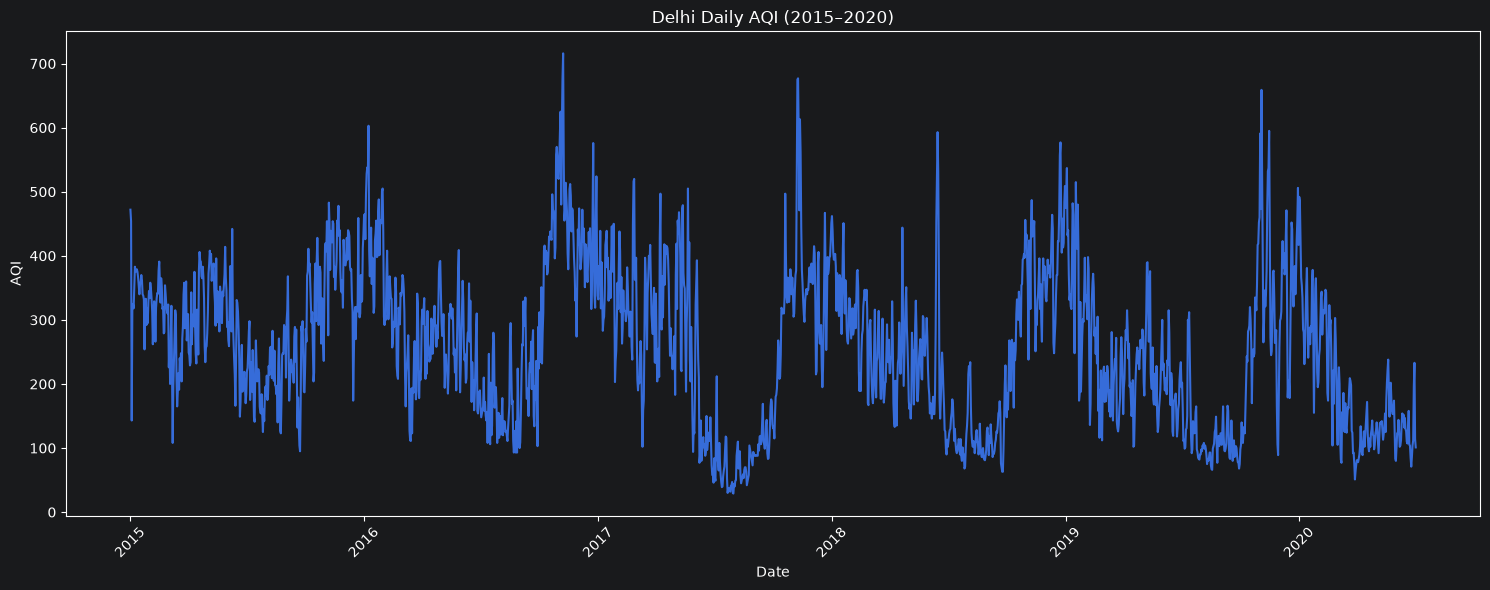

In [22]:
plt.figure(figsize=(15, 6))

plt.plot(delhi_ts.index, delhi_ts["AQI"])

plt.title("Delhi Daily AQI (2015–2020)")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 12.2 AQI Distribution

The time-series plot shows how AQI changes over time, but it does not tell us how AQI values are distributed. We therefore examine the distribution of AQI using a histogram and summary statistics.

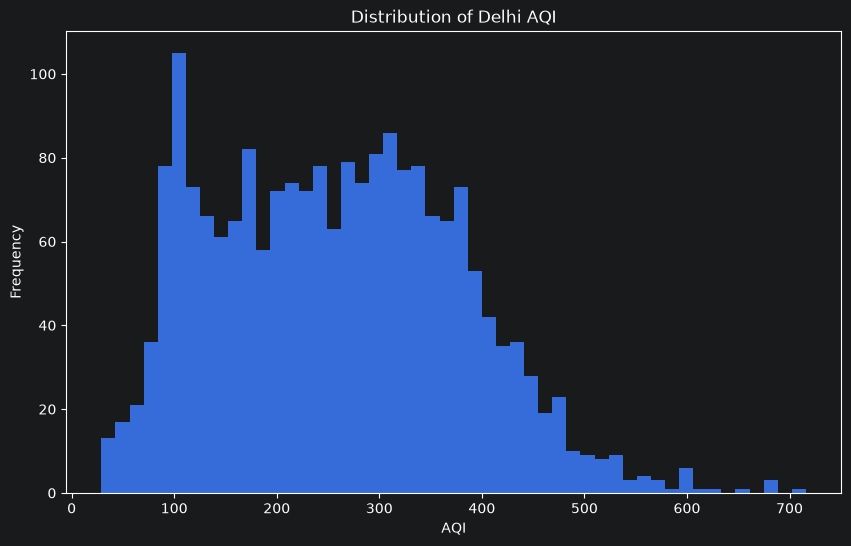

In [23]:
plt.figure(figsize=(10, 6))

plt.hist(delhi_ts["AQI"], bins=50)

plt.title("Distribution of Delhi AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()

In [24]:
delhi_ts["AQI"].describe()

count    2009.000000
mean      258.621453
std       119.897735
min        29.000000
25%       159.000000
50%       257.000000
75%       345.000000
max       716.000000
Name: AQI, dtype: float64

### 12.3 AQI Boxplot

A boxplot helps us identify the median, spread, and potential extreme AQI observations. Extreme values are particularly important in air-quality forecasting because pollution episodes can strongly influence forecasting models.

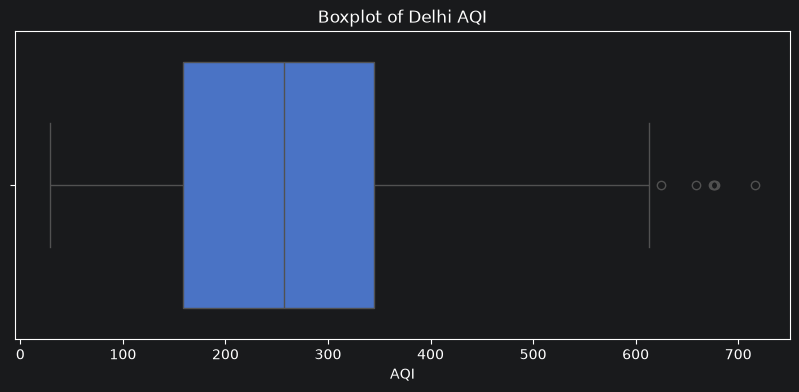

In [25]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=delhi_ts["AQI"])

plt.title("Boxplot of Delhi AQI")
plt.xlabel("AQI")

plt.show()

### 12.4 Year-wise AQI Analysis

We now aggregate AQI by year to investigate whether the overall level of air pollution has changed over the observation period.

In [26]:
yearly_aqi = delhi_ts.groupby(
    delhi_ts.index.year
)["AQI"].agg(["mean", "median", "min", "max"])

yearly_aqi

,mean,median,min,max
Date,,,,
2015,297.024658,303.0,95.0,483.0
2016,301.035519,292.5,93.0,716.0
2017,252.247945,274.0,29.0,677.0
2018,249.158904,243.0,63.0,593.0
2019,232.104110,209.0,66.0,659.0
2020,181.672131,148.0,51.0,492.0


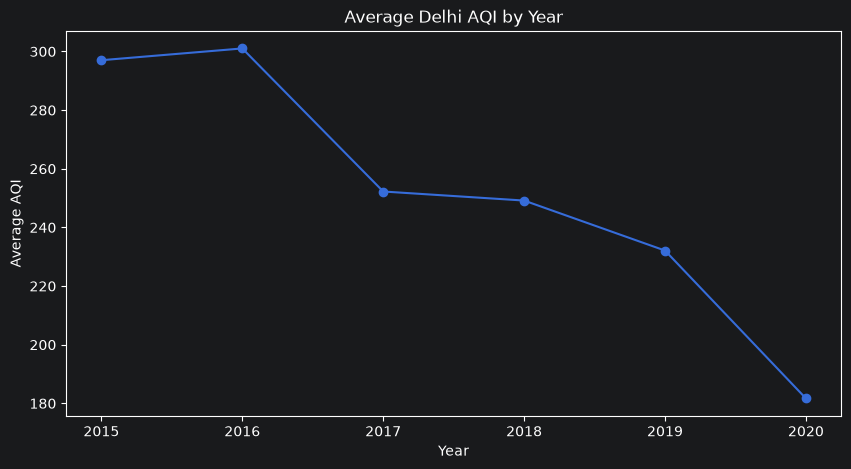

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(yearly_aqi.index, yearly_aqi["mean"], marker="o")

plt.title("Average Delhi AQI by Year")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.xticks(yearly_aqi.index)

plt.show()

### 12.5 Monthly AQI Pattern

To investigate possible seasonality, we calculate the average AQI for each calendar month across all available years. Repeated differences between months may indicate a seasonal pattern that could be useful for forecasting.

In [28]:
monthly_aqi = delhi_ts.groupby(
    delhi_ts.index.month
)["AQI"].mean()

monthly_aqi

Date
1     360.387097
2     298.829412
3     222.623656
4     248.444444
5     258.693548
6     198.963889
7     137.839744
8     131.103226
9     157.426667
10    312.329032
11    401.953333
12    371.206452
Name: AQI, dtype: float64

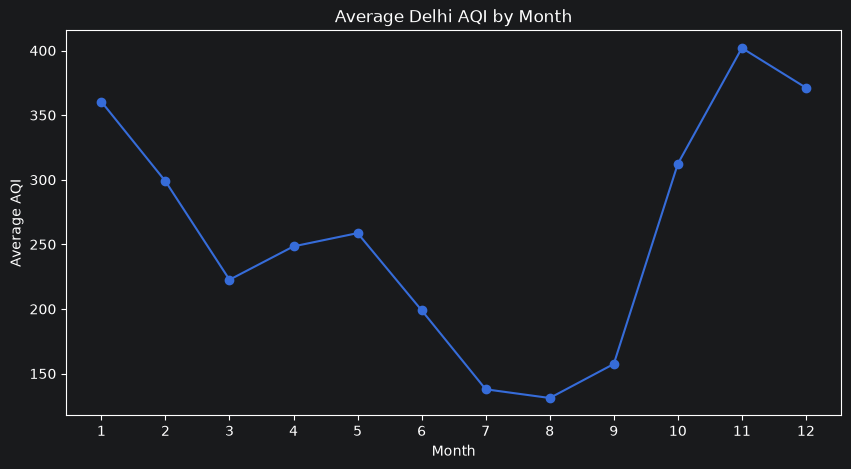

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_aqi.index,
    monthly_aqi.values,
    marker="o"
)

plt.title("Average Delhi AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))

plt.show()

## 13. Time Series Decomposition

The exploratory analysis suggests that Delhi AQI contains both a long-term trend and a strong recurring seasonal pattern. Time-series decomposition allows us to separate the observed series into different components so that we can understand the underlying structure more clearly.

The series can be represented conceptually as:

Observed = Trend + Seasonality + Residual

We will use decomposition to examine the trend, seasonal pattern, and remaining irregular component separately.

In [30]:
delhi_ts = delhi_ts.asfreq("D")

In [31]:
print(delhi_ts.index.freq)

<Day>


In [32]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [33]:
decomposition = seasonal_decompose(
    delhi_ts["AQI"],
    model="additive",
    period=365
)

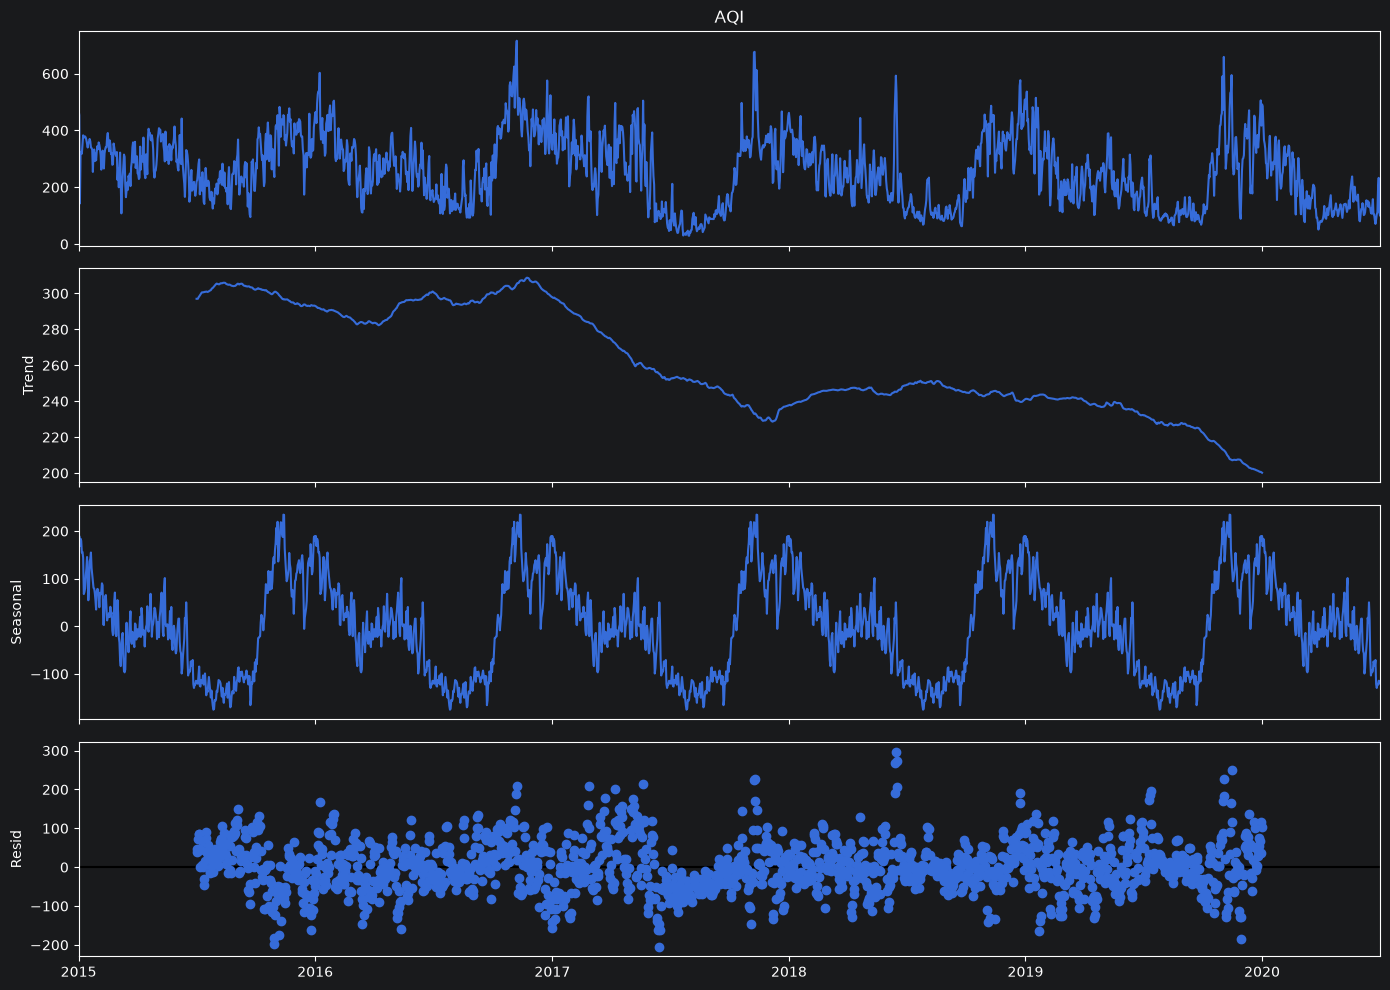

In [34]:
fig = decomposition.plot()

fig.set_size_inches(14, 10)

plt.tight_layout()
plt.show()

## 14. Rolling Mean and Rolling Standard Deviation

A stationary time series should have relatively stable statistical properties over time. As an initial visual assessment, we will examine the rolling mean and rolling standard deviation of AQI. Changes in these statistics over time may indicate the presence of trend or changing variability.

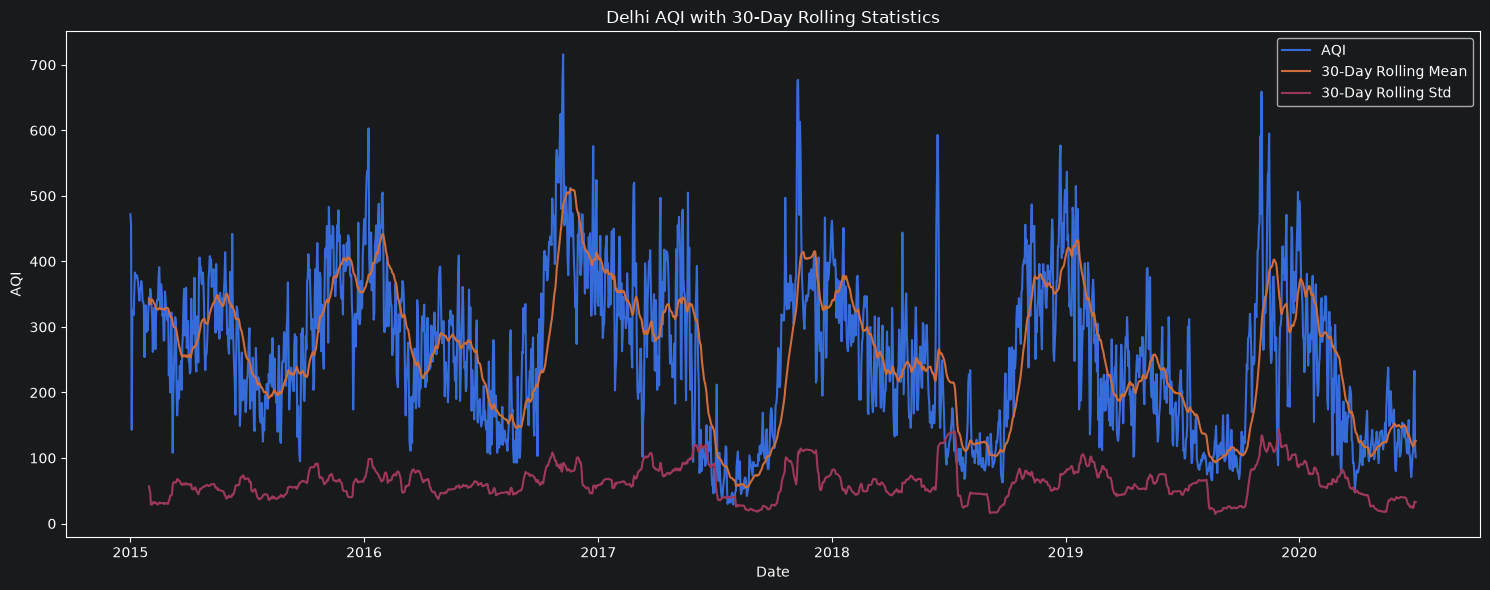

In [35]:
rolling_mean = delhi_ts["AQI"].rolling(window=30).mean()
rolling_std = delhi_ts["AQI"].rolling(window=30).std()

plt.figure(figsize=(15, 6))

plt.plot(delhi_ts.index, delhi_ts["AQI"], label="AQI")
plt.plot(rolling_mean.index, rolling_mean, label="30-Day Rolling Mean")
plt.plot(rolling_std.index, rolling_std, label="30-Day Rolling Std")

plt.title("Delhi AQI with 30-Day Rolling Statistics")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

## 15. Stationarity Analysis

Stationarity is an important concept in time-series forecasting. A stationary time series has statistical properties such as its mean and variance that remain relatively stable over time.

From the rolling statistics and decomposition, the Delhi AQI series appears to contain trend and seasonality, suggesting that it may not be stationary. We will now formally test this assumption using the Augmented Dickey-Fuller (ADF) test.

In [36]:
from statsmodels.tsa.stattools import adfuller

In [37]:
adf_result = adfuller(delhi_ts["AQI"])

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Number of Lags Used:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("\nCritical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -3.431934347253973
p-value: 0.009917226121156647
Number of Lags Used: 17
Number of Observations: 1991

Critical Values:
1%: -3.4336386745240652
5%: -2.8629927557359443
10%: -2.5675433856598793


## 16. Autocorrelation and Partial Autocorrelation Analysis

The ADF test indicates that the Delhi AQI series is stationary at the 5% significance level, so we will initially consider models with no regular differencing. We now examine the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) to understand the dependence between current AQI values and their past observations.

The ACF helps identify the correlation between the current observation and its previous lagged observations, while the PACF measures the direct relationship between an observation and a specific lag after accounting for the effects of intermediate lags.

These plots will help us identify suitable candidate AR and MA orders for our ARIMA/SARIMA models.

In [38]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

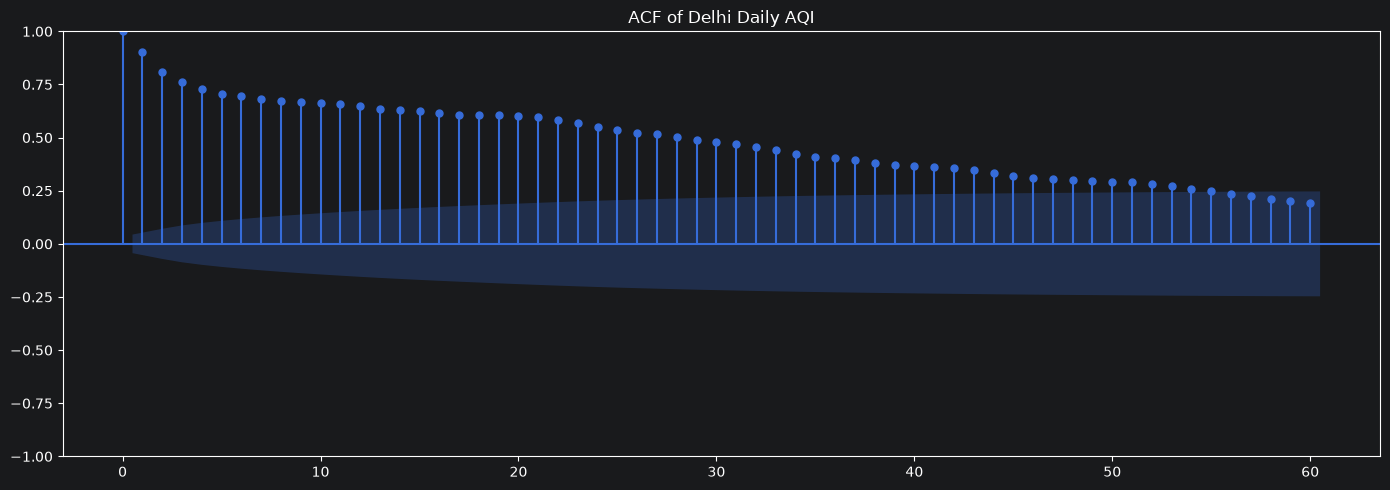

In [39]:
fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    delhi_ts["AQI"],
    lags=60,
    ax=ax
)

ax.set_title("ACF of Delhi Daily AQI")
plt.tight_layout()
plt.show()

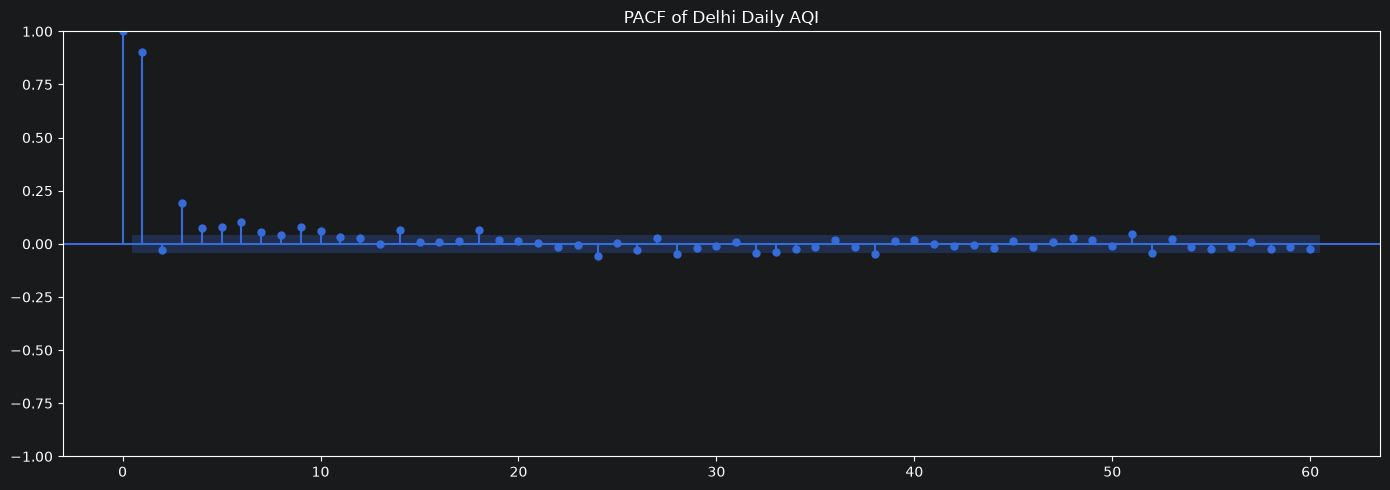

In [40]:
fig, ax = plt.subplots(figsize=(14, 5))

plot_pacf(
    delhi_ts["AQI"],
    lags=60,
    ax=ax,
    method="ywm"
)

ax.set_title("PACF of Delhi Daily AQI")
plt.tight_layout()
plt.show()

## 17. Seasonal Autocorrelation Analysis

The ACF analysis shows strong short-term autocorrelation, while our earlier EDA and decomposition revealed a strong annual seasonal pattern. Since the data is recorded daily, an annual seasonal cycle corresponds approximately to 365 observations. We will therefore extend the ACF analysis to investigate autocorrelation at seasonal lags and determine whether an explicit seasonal component should be included in our forecasting models.

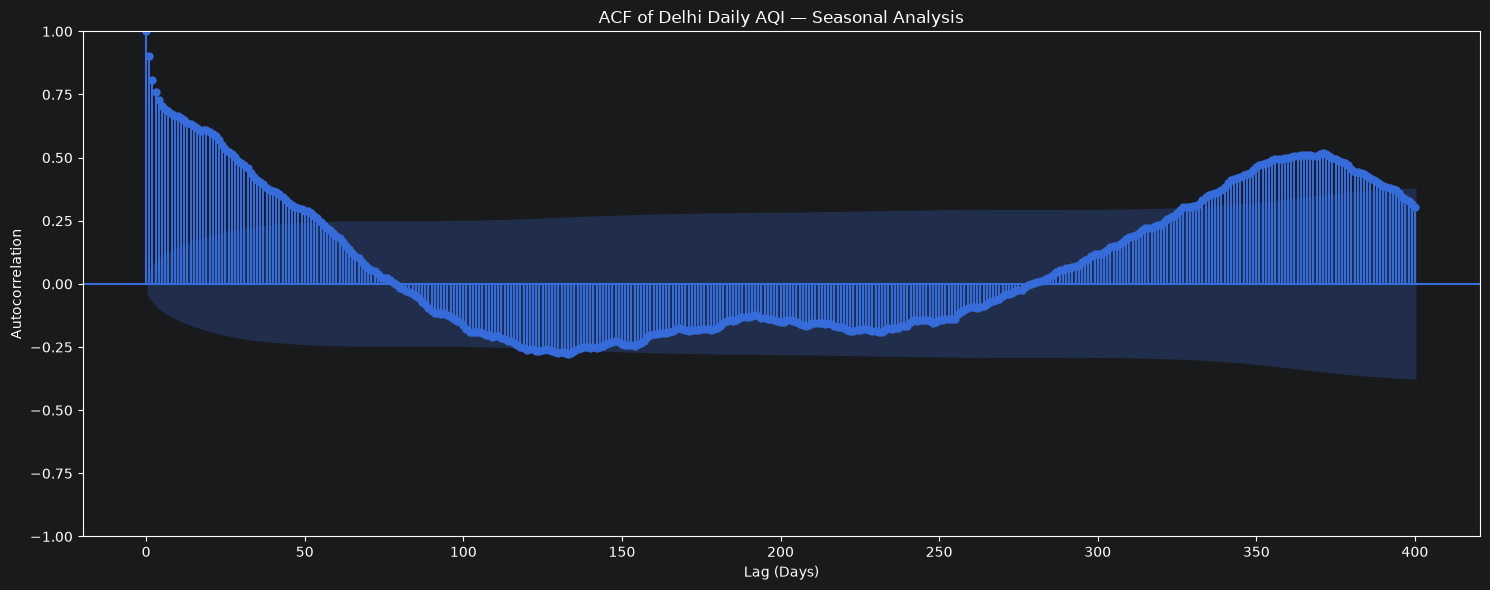

In [41]:
fig, ax = plt.subplots(figsize=(15, 6))

plot_acf(
    delhi_ts["AQI"],
    lags=400,
    ax=ax
)

ax.set_title("ACF of Delhi Daily AQI — Seasonal Analysis")
ax.set_xlabel("Lag (Days)")
ax.set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

In [42]:
for lag in [7, 30, 90, 180, 365]:
    print(f"Lag {lag}: {delhi_ts['AQI'].autocorr(lag=lag):.4f}")

Lag 7: 0.6867
Lag 30: 0.4847
Lag 90: -0.1098
Lag 180: -0.1843
Lag 365: 0.6236


In [43]:
print("Lag 7 correlation:", delhi_ts["AQI"].autocorr(lag=7))
print("Lag 14 correlation:", delhi_ts["AQI"].autocorr(lag=14))
print("Lag 30 correlation:", delhi_ts["AQI"].autocorr(lag=30))
print("Lag 365 correlation:", delhi_ts["AQI"].autocorr(lag=365))

Lag 7 correlation: 0.6867268923534301
Lag 14 correlation: 0.6367125255113598
Lag 30 correlation: 0.48470969649051504
Lag 365 correlation: 0.6236395476158292


## 18. Train-Test Split for Forecasting

Before developing forecasting models, we divide the time series chronologically into training and testing periods. Unlike traditional machine-learning problems, time-series data must not be randomly shuffled because future observations cannot be used to predict the past.

The training set will contain the earlier observations used to develop the models, while the test set will contain the most recent observations and will simulate unseen future data.

We will reserve the final **365 days** as the test set so that the model is evaluated on a complete annual cycle.

In [44]:
test_size = 365

train = delhi_ts.iloc[:-test_size].copy()
test = delhi_ts.iloc[-test_size:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 1644
Testing observations: 365

Training period:
2015-01-01 00:00:00 to 2019-07-02 00:00:00

Testing period:
2019-07-03 00:00:00 to 2020-07-01 00:00:00


## 19. Training and Testing Periods

The following visualization shows the chronological separation between the training and testing periods. The test period represents the future observations that will remain unseen during model training.

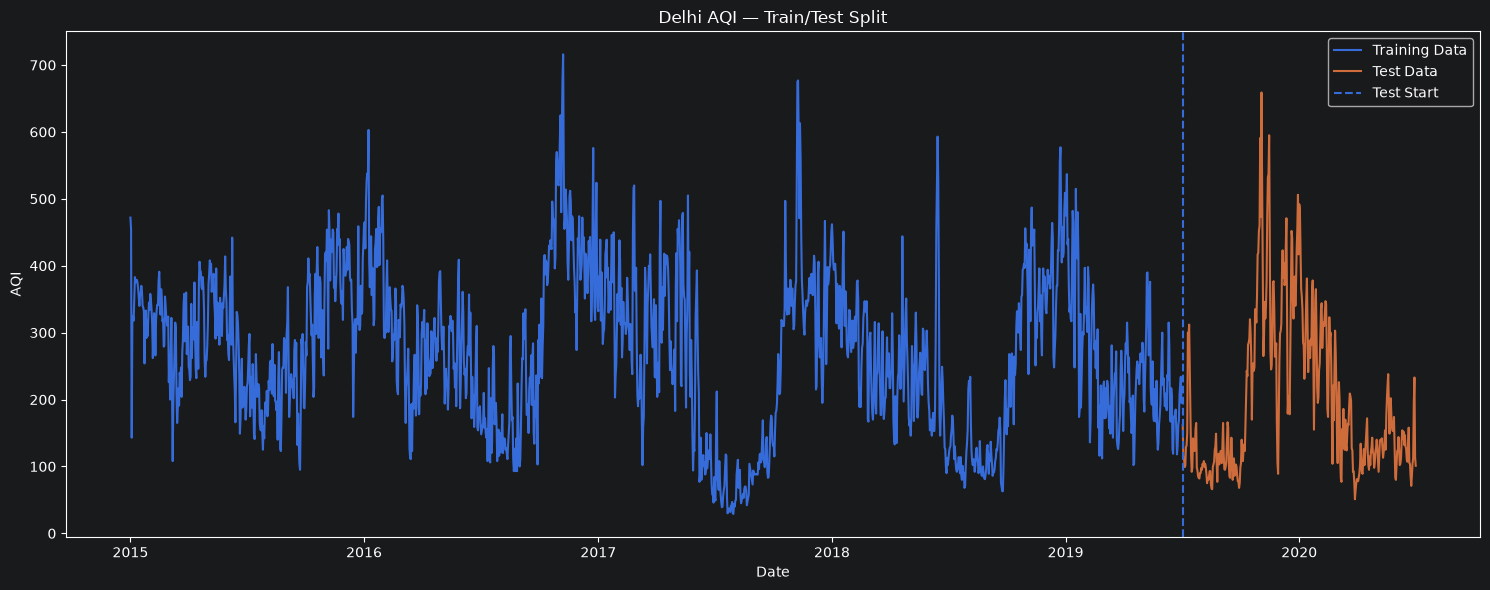

In [45]:
plt.figure(figsize=(15, 6))

plt.plot(train.index, train["AQI"], label="Training Data")
plt.plot(test.index, test["AQI"], label="Test Data")

plt.axvline(
    test.index[0],
    linestyle="--",
    label="Test Start"
)

plt.title("Delhi AQI — Train/Test Split")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

## 20. Baseline Forecasting

Before developing advanced forecasting models, we establish simple baseline models. These baselines provide a reference point for evaluating whether more sophisticated models actually provide meaningful predictive improvement.

We will use two baseline forecasting strategies:

1. **Naive Forecast** — the forecast for the next day is equal to the most recently observed AQI.
2. **Seasonal Naive Forecast** — the forecast is based on the AQI observed approximately one year earlier.

The seasonal naive model is particularly relevant because our exploratory analysis revealed strong annual seasonality.

### 20.1 Naive Forecast

The naive method assumes that the most recent observed value is the best prediction of the next value. Although extremely simple, it is an important benchmark for time-series forecasting.

In [46]:
naive_forecast = train["AQI"].iloc[-1]

naive_predictions = np.repeat(
    naive_forecast,
    len(test)
)

naive_predictions = pd.Series(
    naive_predictions,
    index=test.index
)

naive_predictions.head()

Date
2019-07-03    202.0
2019-07-04    202.0
2019-07-05    202.0
2019-07-06    202.0
2019-07-07    202.0
Freq: D, dtype: float64

### 20.2 Seasonal Naive Forecast

The seasonal naive method predicts the current value using the observation from the corresponding position in the previous seasonal cycle. Since our data is daily and we observed strong annual seasonality, we use a seasonal period of 365 days.

In [47]:
seasonal_period = 365

seasonal_naive_predictions = delhi_ts["AQI"].shift(
    seasonal_period
).loc[test.index]

seasonal_naive_predictions.head()

Date
2019-07-03    122.0
2019-07-04    128.0
2019-07-05    130.0
2019-07-06    147.0
2019-07-07    155.0
Freq: D, Name: AQI, dtype: float64

In [48]:
print("Missing seasonal naive predictions:",
      seasonal_naive_predictions.isna().sum())

Missing seasonal naive predictions: 0


### 20.3 Baseline Forecast Comparison

We compare the actual AQI values in the test period with the predictions generated by the naive and seasonal naive methods.

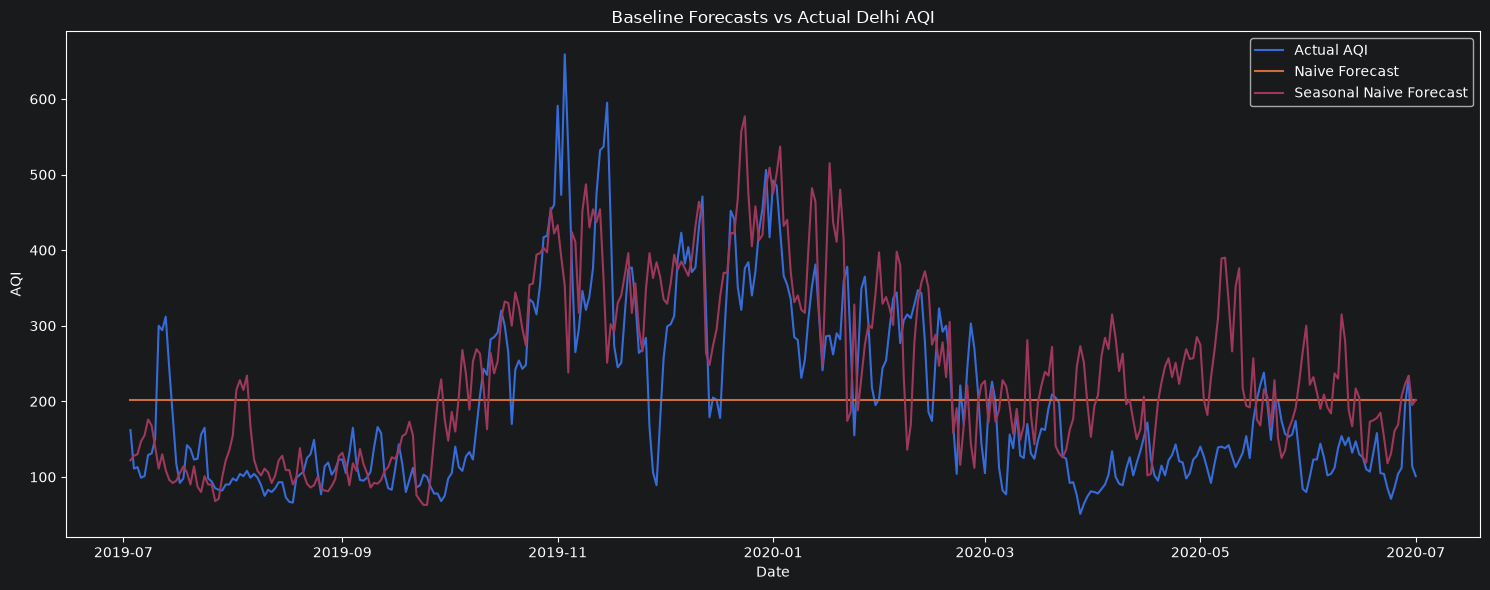

In [49]:
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    test.index,
    naive_predictions,
    label="Naive Forecast"
)

plt.plot(
    test.index,
    seasonal_naive_predictions,
    label="Seasonal Naive Forecast"
)

plt.title("Baseline Forecasts vs Actual Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

### 20.4 Evaluation Metrics

We will evaluate the baseline forecasts using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE). These metrics allow us to compare forecasting performance consistently across all models developed later.

In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

In [51]:
naive_metrics = evaluate_forecast(
    test["AQI"],
    naive_predictions
)

seasonal_naive_metrics = evaluate_forecast(
    test["AQI"],
    seasonal_naive_predictions
)

baseline_results = pd.DataFrame(
    [naive_metrics, seasonal_naive_metrics],
    index=["Naive", "Seasonal Naive"]
)

baseline_results

,MAE,RMSE,MAPE
Naive,99.013699,118.178110,62.695832
Seasonal Naive,75.619178,98.415822,51.659498


# 21. ARIMA Forecasting

After establishing naive and seasonal-naive baselines, we now develop our first statistical forecasting model using ARIMA (AutoRegressive Integrated Moving Average).

ARIMA models a time series using three components:

- **AR (p)** — relationship between the current value and its previous observations.
- **I (d)** — differencing used to achieve stationarity.
- **MA (q)** — relationship between the current value and previous forecast errors.

The ARIMA model is represented as:

ARIMA(p, d, q)

The ADF test performed earlier produced a p-value of approximately 0.0099, providing evidence that the AQI series is stationary at the 5% significance level. Therefore, we will initially investigate models with `d = 0`.

The ACF and PACF suggested strong short-term autoregressive behavior, so we will begin by testing small ARIMA parameter combinations rather than assuming a single model from the plots.

In [52]:
from statsmodels.tsa.arima.model import ARIMA

In [53]:
arima_100 = ARIMA(
    train["AQI"],
    order=(1, 0, 0)
).fit()

print(arima_100.summary())

                               SARIMAX Results                                
Dep. Variable:                    AQI   No. Observations:                 1644
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -8853.100
Date:                Mon, 17 Aug 2026   AIC                          17712.199
Time:                        13:14:33   BIC                          17728.414
Sample:                    01-01-2015   HQIC                         17718.212
                         - 07-02-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        271.6085     12.686     21.410      0.000     246.745     296.472
ar.L1          0.8916      0.012     75.251      0.000       0.868       0.915
sigma2      2783.3050     72.177     38.562      0.0

In [54]:
arima_100_forecast = arima_100.forecast(
    steps=len(test)
)

arima_100_forecast.index = test.index

In [55]:
arima_100_metrics = evaluate_forecast(
    test["AQI"],
    arima_100_forecast
)

arima_100_metrics

{'MAE': 121.5453899592342,
 'RMSE': np.float64(136.8608415229816),
 'MAPE': np.float64(94.61384284878561)}

In [56]:
results = pd.DataFrame(
    {
        "Naive": naive_metrics,
        "Seasonal Naive": seasonal_naive_metrics,
        "ARIMA(1,0,0)": arima_100_metrics
    }
).T

results

,MAE,RMSE,MAPE
Naive,99.013699,118.178110,62.695832
Seasonal Naive,75.619178,98.415822,51.659498
"ARIMA(1,0,0)",121.545390,136.860842,94.613843


In [57]:
arima_100 = ARIMA(
    train["AQI"],
    order=(1, 0, 0)
).fit()

In [58]:
arima_100_forecast = arima_100.forecast(steps=len(test))
arima_100_forecast.index = test.index

In [59]:
arima_100_metrics = evaluate_forecast(
    test["AQI"],
    arima_100_forecast
)

arima_100_metrics

{'MAE': 121.5453899592342,
 'RMSE': np.float64(136.8608415229816),
 'MAPE': np.float64(94.61384284878561)}

## 22. Comparing ARIMA Model Specifications

ARIMA(1,0,0) performed worse than both baseline models, indicating that a simple autoregressive structure is not sufficient to capture the behavior of Delhi AQI. We will therefore compare several low-order ARIMA specifications. Since the ADF test provided evidence of stationarity, we will initially keep `d = 0` and vary the autoregressive and moving-average components.

The models will be compared using both information criteria (AIC/BIC) and out-of-sample forecasting metrics.

In [60]:
arima_orders = [
    (1, 0, 0),
    (2, 0, 0),
    (3, 0, 0),
    (1, 0, 1),
    (2, 0, 1),
    (1, 0, 2),
    (2, 0, 2)
]

In [61]:
arima_results = []

for order in arima_orders:
    print(f"Fitting ARIMA{order}...")

    model = ARIMA(
        train["AQI"],
        order=order
    ).fit()

    forecast = model.forecast(steps=len(test))
    forecast.index = test.index

    metrics = evaluate_forecast(
        test["AQI"],
        forecast
    )

    arima_results.append({
        "Model": f"ARIMA{order}",
        "AIC": model.aic,
        "BIC": model.bic,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MAPE": metrics["MAPE"]
    })

Fitting ARIMA(1, 0, 0)...
Fitting ARIMA(2, 0, 0)...
Fitting ARIMA(3, 0, 0)...
Fitting ARIMA(1, 0, 1)...
Fitting ARIMA(2, 0, 1)...


/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Fitting ARIMA(1, 0, 2)...
Fitting ARIMA(2, 0, 2)...


In [62]:
arima_results_df = pd.DataFrame(arima_results)

arima_results_df.sort_values("RMSE")

,Model,AIC,BIC,MAE,RMSE,MAPE
6,"ARIMA(2, 0, 2)",17589.130580,17621.559906,114.198056,128.918109,86.160062
5,"ARIMA(1, 0, 2)",17626.441125,17653.465563,119.034835,134.003291,92.040589
2,"ARIMA(3, 0, 0)",17650.916724,17677.941162,121.002425,136.238362,94.069858
0,"ARIMA(1, 0, 0)",17712.199416,17728.414079,121.545390,136.860842,94.613843
1,"ARIMA(2, 0, 0)",17714.092786,17735.712336,121.564836,136.881363,94.632178
3,"ARIMA(1, 0, 1)",17714.009946,17735.629496,121.583089,136.900894,94.650155
4,"ARIMA(2, 0, 1)",17703.617272,17730.641709,121.674364,136.991221,94.735720


## 22. Seasonal ARIMA (SARIMA)

The ARIMA experiments show that even the best non-seasonal ARIMA model, ARIMA(2,0,2), performs worse than the seasonal-naive benchmark. This suggests that the strong seasonal structure identified during exploratory analysis is not being adequately captured by ordinary ARIMA.

We therefore move to SARIMA (Seasonal ARIMA), which extends ARIMA by explicitly modeling repeating seasonal behavior. The SARIMA model is represented as:

SARIMA(p,d,q)(P,D,Q,s)

where (p,d,q) represent the non-seasonal components, (P,D,Q) represent the seasonal components, and s represents the seasonal period.

Our analysis identified both strong weekly autocorrelation at lag 7 and strong annual autocorrelation at lag 365. We will begin with a weekly seasonal model because a seasonal period of 7 is computationally much more practical, and then evaluate whether additional methods are required to capture the longer annual pattern.

### 22.1 SARIMA with Weekly Seasonality

We begin with a SARIMA(1,0,1)(1,0,1,7) model. The non-seasonal component captures short-term AQI dynamics, while the seasonal component captures dependencies that repeat every seven days.

We use `d = 0` because the ADF test provided evidence of stationarity, and initially use `D = 0` because we have not established a need for seasonal differencing.

In [63]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [64]:
sarima_101_101_7 = SARIMAX(
    train["AQI"],
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

print(sarima_101_101_7.summary())

                                     SARIMAX Results                                     
Dep. Variable:                               AQI   No. Observations:                 1644
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood               -8821.783
Date:                           Mon, 17 Aug 2026   AIC                          17653.566
Time:                                   13:14:35   BIC                          17680.563
Sample:                               01-01-2015   HQIC                         17663.580
                                    - 07-02-2019                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9842      0.004    247.952      0.000       0.976       0.992
ma.L1         -0.0558      0.020     -2.740

In [65]:
sarima_forecast = sarima_101_101_7.forecast(
    steps=len(test)
)

sarima_forecast.index = test.index

In [66]:
sarima_metrics = evaluate_forecast(
    test["AQI"],
    sarima_forecast
)

sarima_metrics

{'MAE': 173.66841026406448,
 'RMSE': np.float64(215.35676675566302),
 'MAPE': np.float64(80.4602932354612)}

In [67]:
results = pd.DataFrame(
    {
        "Naive": naive_metrics,
        "Seasonal Naive": seasonal_naive_metrics,
        "ARIMA(2,0,2)": arima_results_df.loc[
            arima_results_df["Model"] == "ARIMA(2, 0, 2)"
        ].iloc[0][["MAE", "RMSE", "MAPE"]].to_dict(),
        "SARIMA(1,0,1)(1,0,1,7)": sarima_metrics
    }
).T

results

,MAE,RMSE,MAPE
Naive,99.013699,118.178110,62.695832
Seasonal Naive,75.619178,98.415822,51.659498
"ARIMA(2,0,2)",114.198056,128.918109,86.160062
"SARIMA(1,0,1)(1,0,1,7)",173.668410,215.356767,80.460293


In [68]:
best_arima_metrics = {
    "MAE": 114.198056,
    "RMSE": 128.918109,
    "MAPE": 86.160062
}

comparison = pd.DataFrame(
    [naive_metrics,
     seasonal_naive_metrics,
     best_arima_metrics,
     sarima_metrics],
    index=[
        "Naive",
        "Seasonal Naive",
        "ARIMA(2,0,2)",
        "SARIMA(1,0,1)(1,0,1,7)"
    ]
)

comparison

,MAE,RMSE,MAPE
Naive,99.013699,118.178110,62.695832
Seasonal Naive,75.619178,98.415822,51.659498
"ARIMA(2,0,2)",114.198056,128.918109,86.160062
"SARIMA(1,0,1)(1,0,1,7)",173.668410,215.356767,80.460293


## 23. SARIMA Forecast vs Actual

The weekly SARIMA model performed substantially worse than the seasonal-naive benchmark. We visualize its predictions against the actual test observations to understand where the model fails and whether the forecast captures the major seasonal movements in AQI.

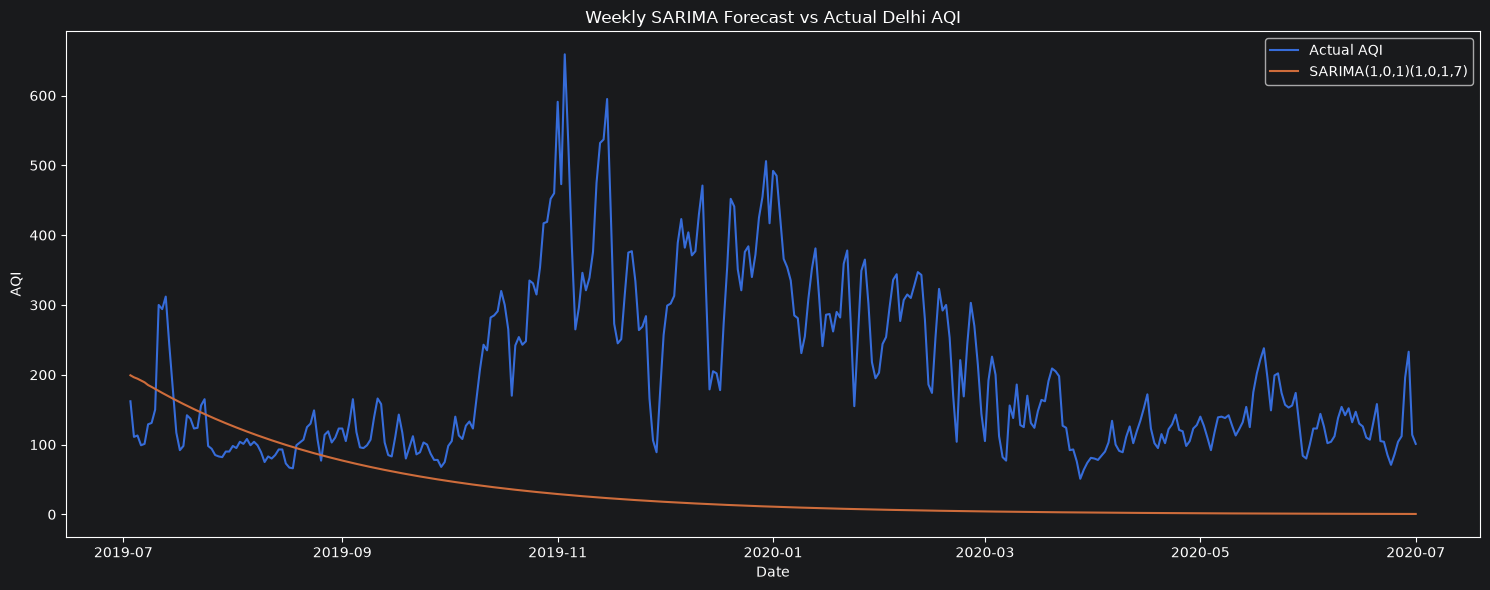

In [69]:
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    test.index,
    sarima_forecast,
    label="SARIMA(1,0,1)(1,0,1,7)"
)

plt.title("Weekly SARIMA Forecast vs Actual Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

In [70]:
print("First 10 predictions:")
print(sarima_forecast.head(10))

print("\nLast 10 predictions:")
print(sarima_forecast.tail(10))

First 10 predictions:
Date
2019-07-03    199.207271
2019-07-04    196.338921
2019-07-05    194.346213
2019-07-06    191.794227
2019-07-07    189.180072
2019-07-08    185.236548
2019-07-09    182.570625
2019-07-10    179.668598
2019-07-11    176.824482
2019-07-12    174.025413
Freq: D, Name: predicted_mean, dtype: float64

Last 10 predictions:
Date
2020-06-22    0.696465
2020-06-23    0.685440
2020-06-24    0.674589
2020-06-25    0.663911
2020-06-26    0.653401
2020-06-27    0.643058
2020-06-28    0.632878
2020-06-29    0.622860
2020-06-30    0.613000
2020-07-01    0.603297
Freq: D, Name: predicted_mean, dtype: float64


## 24. Annual Seasonality Using Fourier Terms

The weekly SARIMA model failed to capture the long-term annual behavior of Delhi AQI. Since the exploratory analysis and ACF showed strong annual seasonality, we now represent the yearly seasonal pattern using Fourier terms.

Fourier terms model seasonality through combinations of sine and cosine functions. This allows a long seasonal cycle such as 365 days to be represented using a relatively small number of parameters.

The Fourier terms will model the annual seasonal component, while an ARIMA error structure will capture short-term temporal dependence. This approach is also known as dynamic harmonic regression.

In [71]:
def create_fourier_features(index, period=365, K=5, start=0):
    t = np.arange(start, start + len(index))

    features = {}

    for k in range(1, K + 1):
        features[f"sin_{k}"] = np.sin(
            2 * np.pi * k * t / period
        )

        features[f"cos_{k}"] = np.cos(
            2 * np.pi * k * t / period
        )

    return pd.DataFrame(
        features,
        index=index
    )

In [72]:
K = 5
period = 365

fourier_train = create_fourier_features(
    train.index,
    period=period,
    K=K,
    start=0
)

fourier_test = create_fourier_features(
    test.index,
    period=period,
    K=K,
    start=len(train)
)

In [73]:
print("Train Fourier shape:", fourier_train.shape)
print("Test Fourier shape:", fourier_test.shape)

fourier_train.head()

Train Fourier shape: (1644, 10)
Test Fourier shape: (365, 10)


,sin_1,cos_1,sin_2,cos_2,sin_3,cos_3,sin_4,cos_4,sin_5,cos_5
Date,,,,,,,,,,
2015-01-01,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
2015-01-02,0.017213,0.999852,0.034422,0.999407,0.051620,0.998667,0.068802,0.997630,0.085965,0.996298
2015-01-03,0.034422,0.999407,0.068802,0.997630,0.103102,0.994671,0.137279,0.990532,0.171293,0.985220
2015-01-04,0.051620,0.998667,0.103102,0.994671,0.154309,0.988023,0.205104,0.978740,0.255353,0.966848
2015-01-05,0.068802,0.997630,0.137279,0.990532,0.205104,0.978740,0.271958,0.962309,0.337523,0.941317


In [74]:
sarimax_fourier = SARIMAX(
    train["AQI"],
    exog=fourier_train,
    order=(2, 0, 2),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

In [75]:
print(sarimax_fourier.summary())

                               SARIMAX Results                                
Dep. Variable:                    AQI   No. Observations:                 1644
Model:               SARIMAX(2, 0, 2)   Log Likelihood               -8738.097
Date:                Mon, 17 Aug 2026   AIC                          17506.194
Time:                        13:14:36   BIC                          17587.240
Sample:                    01-01-2015   HQIC                         17536.251
                         - 07-02-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin_1         48.3806     18.136      2.668      0.008      12.834      83.927
cos_1        104.6278     14.604      7.164      0.000      76.004     133.252
sin_2        -67.7449      9.206     -7.359      0.0

In [76]:
fourier_forecast = sarimax_fourier.forecast(
    steps=len(test),
    exog=fourier_test
)

fourier_forecast.index = test.index

In [77]:
fourier_metrics = evaluate_forecast(
    test["AQI"],
    fourier_forecast
)

fourier_metrics

{'MAE': 76.7472722805399,
 'RMSE': np.float64(95.81558042907872),
 'MAPE': np.float64(52.88682655934319)}

In [78]:
comparison = pd.DataFrame(
    [
        naive_metrics,
        seasonal_naive_metrics,
        best_arima_metrics,
        sarima_metrics,
        fourier_metrics
    ],
    index=[
        "Naive",
        "Seasonal Naive",
        "ARIMA(2,0,2)",
        "SARIMA(1,0,1)(1,0,1,7)",
        "Fourier + ARIMA(2,0,2)"
    ]
)

comparison.sort_values("RMSE")

,MAE,RMSE,MAPE
"Fourier + ARIMA(2,0,2)",76.747272,95.815580,52.886827
Seasonal Naive,75.619178,98.415822,51.659498
Naive,99.013699,118.178110,62.695832
"ARIMA(2,0,2)",114.198056,128.918109,86.160062
"SARIMA(1,0,1)(1,0,1,7)",173.668410,215.356767,80.460293


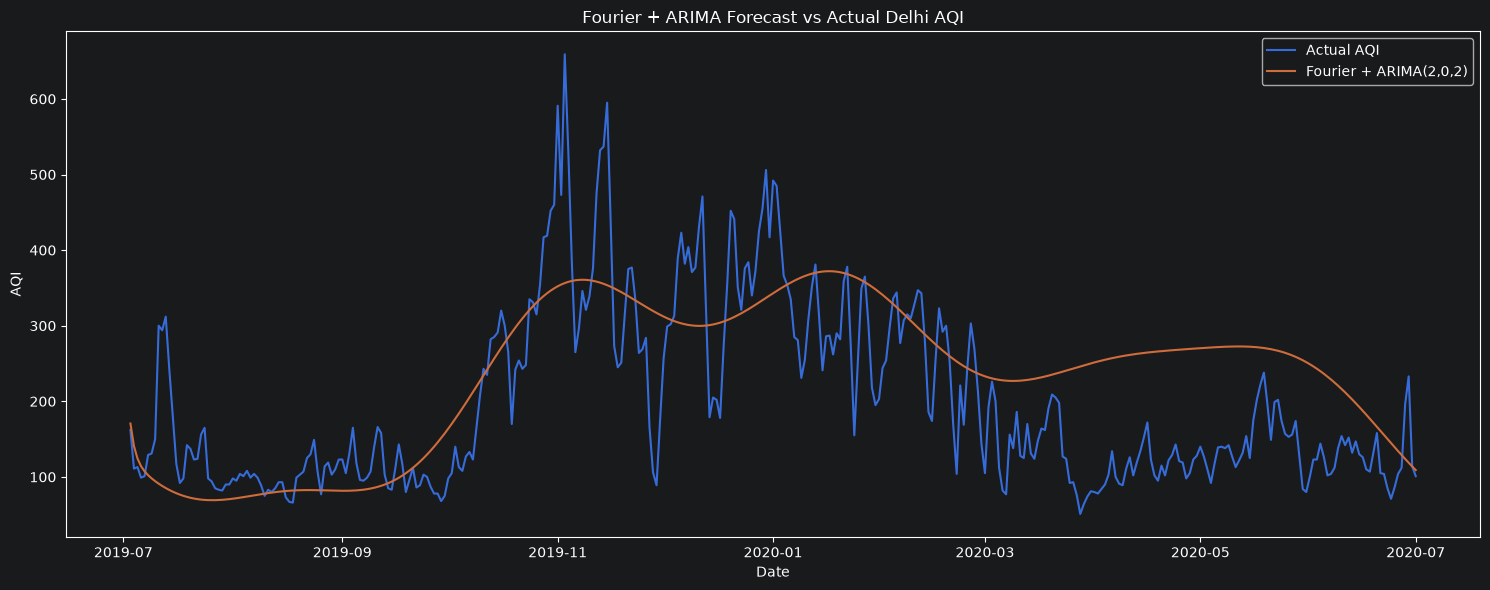

In [79]:
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    test.index,
    fourier_forecast,
    label="Fourier + ARIMA(2,0,2)"
)

plt.title("Fourier + ARIMA Forecast vs Actual Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

## 25. Validation Strategy for Model Selection

The initial test set is reserved for final model evaluation and should not be repeatedly used for tuning model parameters. Therefore, we further divide the training data into a training subset and a validation set.

The validation set will be used to select the Fourier order and other model configurations. After selecting the best configuration, the model will be refitted using the complete training data and evaluated once on the untouched test set.

In [80]:
validation_size = 365

train_sub = train.iloc[:-validation_size].copy()
validation = train.iloc[-validation_size:].copy()

print("Training subset:", len(train_sub))
print("Validation:", len(validation))
print("Final test:", len(test))

print("\nTraining subset:")
print(train_sub.index.min(), "to", train_sub.index.max())

print("\nValidation:")
print(validation.index.min(), "to", validation.index.max())

print("\nFinal test:")
print(test.index.min(), "to", test.index.max())

Training subset: 1279
Validation: 365
Final test: 365

Training subset:
2015-01-01 00:00:00 to 2018-07-02 00:00:00

Validation:
2018-07-03 00:00:00 to 2019-07-02 00:00:00

Final test:
2019-07-03 00:00:00 to 2020-07-01 00:00:00


In [81]:
fourier_orders = [2, 3, 5, 7, 10]

validation_results = []

for K in fourier_orders:

    print(f"Fitting Fourier K={K}...")

    X_train_sub = create_fourier_features(
        train_sub.index,
        period=365,
        K=K,
        start=0
    )

    X_validation = create_fourier_features(
        validation.index,
        period=365,
        K=K,
        start=len(train_sub)
    )

    model = SARIMAX(
        train_sub["AQI"],
        exog=X_train_sub,
        order=(2, 0, 2),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit()

    forecast = model.forecast(
        steps=len(validation),
        exog=X_validation
    )

    forecast.index = validation.index

    metrics = evaluate_forecast(
        validation["AQI"],
        forecast
    )

    validation_results.append({
        "K": K,
        "AIC": model.aic,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MAPE": metrics["MAPE"]
    })

Fitting Fourier K=2...
Fitting Fourier K=3...


/Users/gyanvi/PycharmProjects/AQI-Time-Series-Forecasting/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Fitting Fourier K=5...
Fitting Fourier K=7...
Fitting Fourier K=10...


In [82]:
validation_results_df = pd.DataFrame(validation_results)

validation_results_df.sort_values("RMSE")

,K,AIC,MAE,RMSE,MAPE
0,2,13689.091441,58.828537,75.565029,27.372870
3,7,13680.847304,60.366677,76.410464,29.207120
2,5,13675.332791,60.039009,76.653956,29.034523
4,10,13689.659119,60.815035,76.932793,29.442599
1,3,13691.727045,63.878605,80.842435,31.060074


In [83]:
validation_results_df.sort_values("RMSE")

,K,AIC,MAE,RMSE,MAPE
0,2,13689.091441,58.828537,75.565029,27.372870
3,7,13680.847304,60.366677,76.410464,29.207120
2,5,13675.332791,60.039009,76.653956,29.034523
4,10,13689.659119,60.815035,76.932793,29.442599
1,3,13691.727045,63.878605,80.842435,31.060074


## 26. Fourier Order Selection

We evaluated Fourier orders K = 2, 3, 5, 7, and 10 using the validation set. The model with K = 2 achieved the lowest MAE, RMSE, and MAPE, indicating the best out-of-sample forecasting performance among the tested configurations.

Although K = 5 produced the lowest AIC, K = 2 was selected because forecasting performance on unseen validation data is the primary criterion for this project. The selected K = 2 configuration also provides a more parsimonious representation of the annual seasonal pattern.

## 27. Final Fourier + ARIMA Model

After selecting the Fourier order using the validation set, we refit the selected model using the complete training data. The final model uses K = 2 Fourier terms to represent annual seasonality and ARIMA(2,0,2) to model short-term temporal dependence.

The final model is then evaluated once on the previously untouched test period.

In [84]:
K_final = 2
period = 365

fourier_train_final = create_fourier_features(
    train.index,
    period=period,
    K=K_final,
    start=0
)

fourier_test_final = create_fourier_features(
    test.index,
    period=period,
    K=K_final,
    start=len(train)
)

In [85]:
print("Training Fourier shape:", fourier_train_final.shape)
print("Test Fourier shape:", fourier_test_final.shape)

Training Fourier shape: (1644, 4)
Test Fourier shape: (365, 4)


In [86]:
final_fourier_arima = SARIMAX(
    train["AQI"],
    exog=fourier_train_final,
    order=(2, 0, 2),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

print(final_fourier_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                    AQI   No. Observations:                 1644
Model:               SARIMAX(2, 0, 2)   Log Likelihood               -8753.670
Date:                Mon, 17 Aug 2026   AIC                          17525.339
Time:                        13:14:41   BIC                          17573.967
Sample:                    01-01-2015   HQIC                         17543.373
                         - 07-02-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin_1         48.6409     21.734      2.238      0.025       6.043      91.239
cos_1        105.4833     18.535      5.691      0.000      69.154     141.812
sin_2        -67.8147     10.712     -6.331      0.0

In [87]:
final_forecast = pd.Series(
    final_fourier_arima.forecast(
        steps=len(test),
        exog=fourier_test_final
    ),
    index=test.index,
    name="AQI"
)

final_forecast.head()

Date
2019-07-03    183.836997
2019-07-04    164.686064
2019-07-05    153.607607
2019-07-06    146.529097
2019-07-07    141.441198
Freq: D, Name: AQI, dtype: float64

In [88]:
final_metrics = evaluate_forecast(
    test["AQI"],
    final_forecast
)

final_metrics

{'MAE': 73.4328705951906,
 'RMSE': np.float64(93.70253670786002),
 'MAPE': np.float64(51.06170446179822)}

In [89]:
final_comparison = pd.DataFrame(
    [
        naive_metrics,
        seasonal_naive_metrics,
        best_arima_metrics,
        sarima_metrics,
        final_metrics
    ],
    index=[
        "Naive",
        "Seasonal Naive",
        "ARIMA(2,0,2)",
        "SARIMA(1,0,1)(1,0,1,7)",
        "Fourier + ARIMA(2,0,2), K=2"
    ]
)

final_comparison.sort_values("RMSE")

,MAE,RMSE,MAPE
"Fourier + ARIMA(2,0,2), K=2",73.432871,93.702537,51.061704
Seasonal Naive,75.619178,98.415822,51.659498
Naive,99.013699,118.178110,62.695832
"ARIMA(2,0,2)",114.198056,128.918109,86.160062
"SARIMA(1,0,1)(1,0,1,7)",173.668410,215.356767,80.460293


## 28. Final Statistical Model Selection

After evaluating multiple forecasting approaches, Fourier + ARIMA(2,0,2) with Fourier order K = 2 achieved the best overall performance on the untouched test set.

The model achieved an MAE of 73.43, RMSE of 93.70, and MAPE of 51.06%. It outperformed both the naive and seasonal-naive baselines as well as the tested ARIMA and weekly SARIMA models across all three evaluation metrics.

The final model combines two components:

1. Fourier terms — capture the smooth annual seasonal pattern in Delhi AQI.
2. ARIMA(2,0,2) — captures short-term temporal dependence and remaining autocorrelation.

The Fourier order K = 2 was selected using a separate validation period rather than the final test set, preventing test-set leakage during model selection.

Therefore, Fourier + ARIMA(2,0,2), K = 2 is selected as the best statistical forecasting model for the next stage of the project.

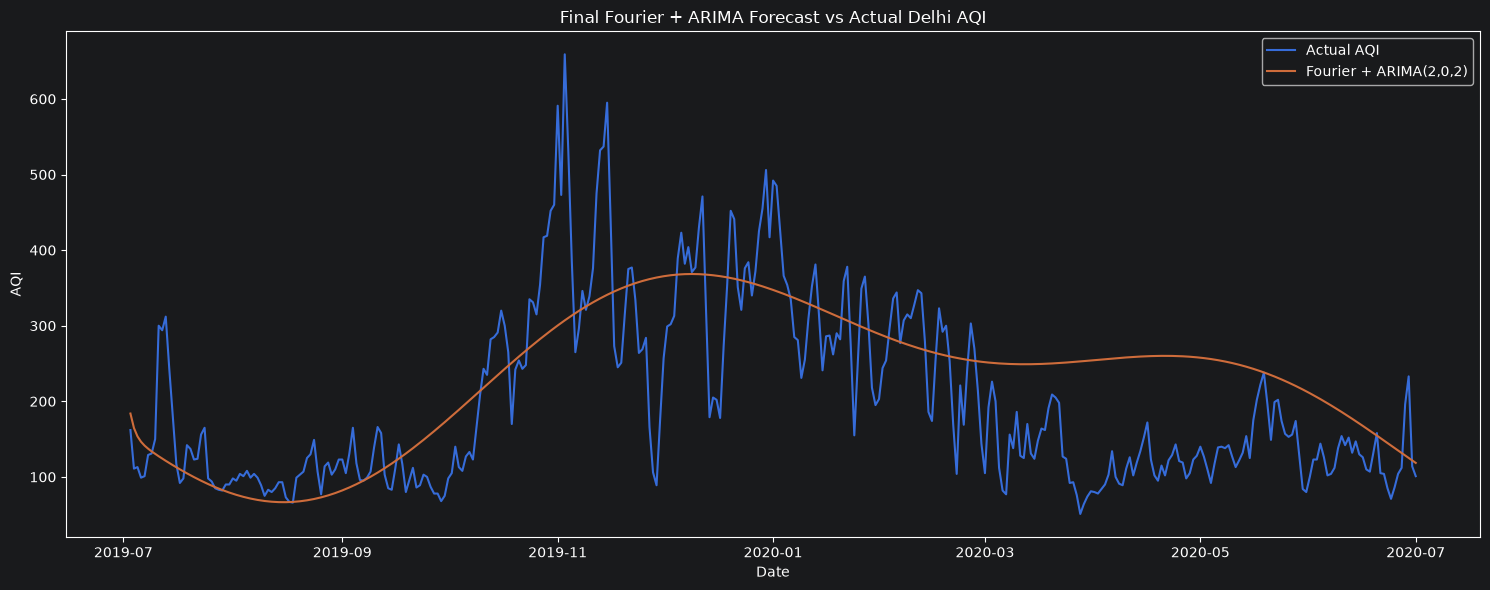

In [90]:
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    test.index,
    final_forecast,
    label="Fourier + ARIMA(2,0,2)"
)

plt.title("Final Fourier + ARIMA Forecast vs Actual Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

In [91]:
rmse_improvement = (
    (seasonal_naive_metrics["RMSE"] - final_metrics["RMSE"])
    / seasonal_naive_metrics["RMSE"]
) * 100

mae_improvement = (
    (seasonal_naive_metrics["MAE"] - final_metrics["MAE"])
    / seasonal_naive_metrics["MAE"]
) * 100

mape_improvement = (
    (seasonal_naive_metrics["MAPE"] - final_metrics["MAPE"])
    / seasonal_naive_metrics["MAPE"]
) * 100

print(f"RMSE improvement: {rmse_improvement:.2f}%")
print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"MAPE improvement: {mape_improvement:.2f}%")

RMSE improvement: 4.79%
MAE improvement: 2.89%
MAPE improvement: 1.16%


## Saving the Preprocessed Delhi AQI Dataset

The cleaned Delhi AQI time series is saved so that the statistical forecasting notebook can use the processed data directly without repeating the data-cleaning workflow.

In [92]:
import os

os.makedirs("../data/processed", exist_ok=True)

delhi_ts.reset_index().to_csv(
    "../data/processed/delhi_aqi_timeseries.csv",
    index=False
)

print("Saved successfully.")
print("Shape:", delhi_ts.shape)

Saved successfully.
Shape: (2009, 1)


# 29. Notebook 1 — Conclusion

This notebook established a complete statistical forecasting framework for Delhi's daily AQI. After performing data quality checks, exploratory time-series analysis, stationarity testing, ACF/PACF analysis, and chronological train-validation-test splitting, several forecasting approaches were evaluated.

The naive model provided the initial benchmark, while the seasonal-naive model demonstrated the importance of annual seasonality. ARIMA models were then evaluated for short-term temporal dependence, followed by weekly SARIMA. Both approaches were unable to outperform the seasonal-naive benchmark.

To explicitly model the strong annual seasonality identified during exploratory analysis, Fourier terms were combined with an ARIMA(2,0,2) error structure. Fourier order was selected using a separate validation period, with K=2 providing the best validation performance. The final model was then refitted on the complete training period and evaluated on the untouched test set.

The final Fourier + ARIMA(2,0,2), K=2 model achieved:

- MAE: 73.43
- RMSE: 93.70
- MAPE: 51.06%

This represents an improvement of approximately 2.89% in MAE, 4.79% in RMSE, and 1.16% in MAPE over the seasonal-naive benchmark.

The results demonstrate that explicitly modeling the annual seasonal structure improves Delhi AQI forecasting compared with simpler statistical approaches. This model will serve as the statistical benchmark for the next stage of the project, where machine-learning models will use lag, rolling, calendar, and seasonal features to determine whether a feature-engineered ML approach can achieve further improvements.

In [93]:
print(delhi_ts.loc["2019-07-03":"2019-07-07"])

              AQI
Date             
2019-07-03  162.0
2019-07-04  111.0
2019-07-05  113.0
2019-07-06   99.0
2019-07-07  101.0


In [94]:
print(delhi_ts.head())
print(delhi_ts.tail())

              AQI
Date             
2015-01-01  472.0
2015-01-02  454.0
2015-01-03  143.0
2015-01-04  319.0
2015-01-05  325.0
              AQI
Date             
2020-06-27  112.0
2020-06-28  196.0
2020-06-29  233.0
2020-06-30  114.0
2020-07-01  101.0


In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/delhi_aqi_timeseries.csv"
)

print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)

         Date    AQI
0  2015-01-01  472.0
1  2015-01-02  454.0
2  2015-01-03  143.0
3  2015-01-04  319.0
4  2015-01-05  325.0
            Date    AQI
2004  2020-06-27  112.0
2005  2020-06-28  196.0
2006  2020-06-29  233.0
2007  2020-06-30  114.0
2008  2020-07-01  101.0
(2009, 2)
Index(['Date', 'AQI'], dtype='str')


In [2]:
print(df["Date"].min())
print(df["Date"].max())

2015-01-01
2020-07-01
